<a href="https://colab.research.google.com/github/haseemathasneemka/Adaptive-NSTFA-Based-Traffic-Data-Imputation-and-Traffic-Flow-Prediction/blob/main/traffic_prediction_imputation_lstm_gru.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# ===== Colab cell 1: upload 4 BJ datasets, impute missing values, save completed CSVs =====
import io, os, warnings
import numpy as np, pandas as pd
from sklearn.linear_model import Ridge
from google.colab import files

OUT_DIR = "/content/completed"
os.makedirs(OUT_DIR, exist_ok=True)
ZERO_AS_MISSING = False      # set True if zeros in your data mean "sensor missing"
DEFAULT_STEPS_PER_DAY = 288  # 5-min data; auto-detected if a timestamp column exists
VAL_MISSING_RATE = 0.10      # extra hidden values used to score the imputation

def impute(X, spd, k=5, iters=3):
    """Stand-in spatio-temporal imputer (replace with NSTFA logic if available)."""
    T, N = X.shape
    miss = np.isnan(X)
    overall = np.nanmean(X)
    colmean = np.nanmean(X, axis=0)
    colmean = np.where(np.isnan(colmean), overall, colmean)
    slot = np.arange(T) % spd
    prof = np.zeros((spd, N))
    for s in range(spd):
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            m = np.nanmean(X[slot == s], axis=0)
        prof[s] = np.where(np.isnan(m), colmean, m)
    interp = pd.DataFrame(X).interpolate(limit=12, limit_area="inside").values
    temporal = np.where(np.isnan(interp), prof[slot], interp)   # temporal + periodic estimate
    F = np.where(miss, temporal, X)
    kk = min(k, N - 1)
    for _ in range(iters):                                      # spatial refinement
        C = np.nan_to_num(np.corrcoef(F.T), nan=-1.0)
        np.fill_diagonal(C, -np.inf)
        nbr = np.argsort(-C, axis=1)[:, :kk]
        newF = F.copy()
        for j in range(N):
            mj = miss[:, j]
            if not mj.any() or mj.all() or kk == 0:
                continue
            r = Ridge(alpha=1.0).fit(F[~mj][:, nbr[j]], X[~mj, j])
            pred = r.predict(F[mj][:, nbr[j]])
            newF[mj, j] = 0.5 * temporal[mj, j] + 0.5 * pred
        F = newF
    return np.clip(F, 0, None)

print("Select your 4 datasets (BJ-I ... BJ-IV CSV files)")
uploaded = files.upload()

for fn, content in uploaded.items():
    name = os.path.splitext(fn)[0]
    df = pd.read_csv(io.BytesIO(content))
    num_cols = df.select_dtypes(include=[np.number]).columns.tolist()
    meta = df.drop(columns=num_cols)
    X = df[num_cols].astype(float).values
    if ZERO_AS_MISSING:
        X[X == 0] = np.nan

    spd = DEFAULT_STEPS_PER_DAY
    for c in meta.columns:
        try:
            t = pd.to_datetime(meta[c])
            step = t.diff().dropna().median().total_seconds()
            spd = int(round(86400 / step)); break
        except Exception:
            pass

    miss_rate = np.isnan(X).mean()
    # --- imputation quality check on artificially hidden known values ---
    rng = np.random.default_rng(0)
    known = np.argwhere(~np.isnan(X))
    hide = known[rng.random(len(known)) < VAL_MISSING_RATE]
    Xh = X.copy(); Xh[hide[:, 0], hide[:, 1]] = np.nan
    Fh = impute(Xh, spd)
    err = Fh[hide[:, 0], hide[:, 1]] - X[hide[:, 0], hide[:, 1]]
    print(f"{name}: shape={X.shape}, missing={miss_rate:.2%}, steps/day={spd}, "
          f"imputation check MAE={np.abs(err).mean():.3f}, RMSE={np.sqrt((err**2).mean()):.3f}")

    # --- final imputation on the real data ---
    F = impute(X, spd)
    out = pd.concat([meta.reset_index(drop=True), pd.DataFrame(F, columns=num_cols)], axis=1)
    out.to_csv(f"{OUT_DIR}/{name}_completed.csv", index=False)
    print(f"  saved -> {OUT_DIR}/{name}_completed.csv  (remaining NaN: {int(np.isnan(F).sum())})")

# optional: download all completed files
os.system(f"cd /content && zip -qr completed.zip completed")
files.download("/content/completed.zip")

Select your 4 datasets (BJ-I ... BJ-IV CSV files)


Saving BJ16_M32x32_T30_In.csv to BJ16_M32x32_T30_In.csv
Saving BJ13_M32x32_T30_In (28).csv to BJ13_M32x32_T30_In (28).csv
Saving BJ14_M32x32_T30_In (3).csv to BJ14_M32x32_T30_In (3).csv
Saving BJ15_M32x32_T30_In.csv to BJ15_M32x32_T30_In.csv
BJ16_M32x32_T30_In: shape=(7219, 1024), missing=0.00%, steps/day=288, imputation check MAE=7.540, RMSE=12.719
  saved -> /content/completed/BJ16_M32x32_T30_In_completed.csv  (remaining NaN: 0)
BJ13_M32x32_T30_In (28): shape=(4887, 1024), missing=0.00%, steps/day=288, imputation check MAE=7.574, RMSE=12.105
  saved -> /content/completed/BJ13_M32x32_T30_In (28)_completed.csv  (remaining NaN: 0)
BJ14_M32x32_T30_In (3): shape=(4779, 1024), missing=0.00%, steps/day=288, imputation check MAE=8.184, RMSE=13.705
  saved -> /content/completed/BJ14_M32x32_T30_In (3)_completed.csv  (remaining NaN: 0)
BJ15_M32x32_T30_In: shape=(5595, 1024), missing=0.00%, steps/day=288, imputation check MAE=8.122, RMSE=12.906
  saved -> /content/completed/BJ15_M32x32_T30_In_co

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [2]:
# ===== Colab cell 2: LSTM traffic-flow prediction on completed datasets =====
import os, glob, io
import numpy as np, pandas as pd, torch, torch.nn as nn
from google.colab import files

MODEL_NAME = "LSTM"
IN_DIR, RES_DIR = "/content/completed", "/content/results"
os.makedirs(RES_DIR, exist_ok=True)
WINDOW, HORIZON = 12, 1
HIDDEN, LAYERS, DROPOUT = 64, 2, 0.2
EPOCHS, PATIENCE, BATCH, LR = 60, 8, 64, 1e-3
dev = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.manual_seed(0); np.random.seed(0)

paths = sorted(glob.glob(f"{IN_DIR}/*_completed.csv"))
if not paths:  # fall back to manual upload of completed CSVs
    up = files.upload()
    os.makedirs(IN_DIR, exist_ok=True)
    for fn, c in up.items():
        open(f"{IN_DIR}/{fn}", "wb").write(c)
    paths = sorted(glob.glob(f"{IN_DIR}/*.csv"))

class Net(nn.Module):
    def __init__(self, n):
        super().__init__()
        self.rnn = nn.LSTM(n, HIDDEN, LAYERS, batch_first=True, dropout=DROPOUT)
        self.fc = nn.Linear(HIDDEN, n)
    def forward(self, x):
        o, _ = self.rnn(x)
        return self.fc(o[:, -1])

def windows(a):
    n = len(a) - WINDOW - HORIZON + 1
    x = np.stack([a[i:i + WINDOW] for i in range(n)])
    y = np.stack([a[i + WINDOW + HORIZON - 1] for i in range(n)])
    return torch.tensor(x, dtype=torch.float32), torch.tensor(y, dtype=torch.float32)

def predict(model, x):
    model.eval(); out = []
    with torch.no_grad():
        for i in range(0, len(x), 512):
            out.append(model(x[i:i + 512].to(dev)).cpu())
    return torch.cat(out).numpy()

rows = []
for p in paths:
    name = os.path.basename(p).replace("_completed.csv", "").replace(".csv", "")
    df = pd.read_csv(p)
    data = df.select_dtypes(include=[np.number]).values.astype(np.float32)
    T, N = data.shape
    a, b = int(T * 0.6), int(T * 0.8)                       # 6:2:2 chronological split
    mu, sd = data[:a].mean(0), data[:a].std(0) + 1e-6
    z = (data - mu) / sd
    xtr, ytr = windows(z[:a]); xva, yva = windows(z[a - WINDOW - HORIZON + 1:b]); xte, yte = windows(z[b - WINDOW - HORIZON + 1:])
    model = Net(N).to(dev)
    opt = torch.optim.Adam(model.parameters(), lr=LR)
    loss_fn = nn.MSELoss()
    best, best_state, bad = 1e9, None, 0
    for ep in range(EPOCHS):
        model.train()
        perm = torch.randperm(len(xtr))
        for i in range(0, len(xtr), BATCH):
            idx = perm[i:i + BATCH]
            opt.zero_grad()
            loss = loss_fn(model(xtr[idx].to(dev)), ytr[idx].to(dev))
            loss.backward(); opt.step()
        vl = float(((predict(model, xva) - yva.numpy()) ** 2).mean())
        if vl < best:
            best, bad = vl, 0
            best_state = {k: v.clone() for k, v in model.state_dict().items()}
        else:
            bad += 1
            if bad >= PATIENCE: break
    model.load_state_dict(best_state)
    pred = predict(model, xte) * sd + mu
    true = yte.numpy() * sd + mu
    mae = np.abs(pred - true).mean(); rmse = np.sqrt(((pred - true) ** 2).mean())
    print(f"[{MODEL_NAME}] {name}: MAE={mae:.4f}  RMSE={rmse:.4f}  (epochs run: {ep + 1})")
    rows.append({"Dataset": name, "Model": MODEL_NAME, "MAE": mae, "RMSE": rmse})

res = pd.DataFrame(rows)
res.to_csv(f"{RES_DIR}/{MODEL_NAME.lower()}_results.csv", index=False)
print(res)

[LSTM] BJ13_M32x32_T30_In (28): MAE=11.6094  RMSE=20.5899  (epochs run: 28)
[LSTM] BJ14_M32x32_T30_In (3): MAE=11.9568  RMSE=21.1818  (epochs run: 47)
[LSTM] BJ15_M32x32_T30_In: MAE=12.0230  RMSE=21.2230  (epochs run: 56)
[LSTM] BJ16_M32x32_T30_In: MAE=11.4721  RMSE=20.7161  (epochs run: 21)
                   Dataset Model        MAE       RMSE
0  BJ13_M32x32_T30_In (28)  LSTM  11.609414  20.589945
1   BJ14_M32x32_T30_In (3)  LSTM  11.956832  21.181767
2       BJ15_M32x32_T30_In  LSTM  12.022981  21.223028
3       BJ16_M32x32_T30_In  LSTM  11.472069  20.716055


In [3]:
# ===== Colab cell 3: GRU traffic-flow prediction on completed datasets =====
import os, glob, io
import numpy as np, pandas as pd, torch, torch.nn as nn
from google.colab import files

MODEL_NAME = "GRU"
IN_DIR, RES_DIR = "/content/completed", "/content/results"
os.makedirs(RES_DIR, exist_ok=True)
WINDOW, HORIZON = 12, 1
HIDDEN, LAYERS, DROPOUT = 64, 2, 0.2
EPOCHS, PATIENCE, BATCH, LR = 60, 8, 64, 1e-3
dev = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.manual_seed(0); np.random.seed(0)

paths = sorted(glob.glob(f"{IN_DIR}/*_completed.csv"))
if not paths:  # fall back to manual upload of completed CSVs
    up = files.upload()
    os.makedirs(IN_DIR, exist_ok=True)
    for fn, c in up.items():
        open(f"{IN_DIR}/{fn}", "wb").write(c)
    paths = sorted(glob.glob(f"{IN_DIR}/*.csv"))

class Net(nn.Module):
    def __init__(self, n):
        super().__init__()
        self.rnn = nn.GRU(n, HIDDEN, LAYERS, batch_first=True, dropout=DROPOUT)
        self.fc = nn.Linear(HIDDEN, n)
    def forward(self, x):
        o, _ = self.rnn(x)
        return self.fc(o[:, -1])

def windows(a):
    n = len(a) - WINDOW - HORIZON + 1
    x = np.stack([a[i:i + WINDOW] for i in range(n)])
    y = np.stack([a[i + WINDOW + HORIZON - 1] for i in range(n)])
    return torch.tensor(x, dtype=torch.float32), torch.tensor(y, dtype=torch.float32)

def predict(model, x):
    model.eval(); out = []
    with torch.no_grad():
        for i in range(0, len(x), 512):
            out.append(model(x[i:i + 512].to(dev)).cpu())
    return torch.cat(out).numpy()

rows = []
for p in paths:
    name = os.path.basename(p).replace("_completed.csv", "").replace(".csv", "")
    df = pd.read_csv(p)
    data = df.select_dtypes(include=[np.number]).values.astype(np.float32)
    T, N = data.shape
    a, b = int(T * 0.6), int(T * 0.8)                       # 6:2:2 chronological split
    mu, sd = data[:a].mean(0), data[:a].std(0) + 1e-6
    z = (data - mu) / sd
    xtr, ytr = windows(z[:a]); xva, yva = windows(z[a - WINDOW - HORIZON + 1:b]); xte, yte = windows(z[b - WINDOW - HORIZON + 1:])
    model = Net(N).to(dev)
    opt = torch.optim.Adam(model.parameters(), lr=LR)
    loss_fn = nn.MSELoss()
    best, best_state, bad = 1e9, None, 0
    for ep in range(EPOCHS):
        model.train()
        perm = torch.randperm(len(xtr))
        for i in range(0, len(xtr), BATCH):
            idx = perm[i:i + BATCH]
            opt.zero_grad()
            loss = loss_fn(model(xtr[idx].to(dev)), ytr[idx].to(dev))
            loss.backward(); opt.step()
        vl = float(((predict(model, xva) - yva.numpy()) ** 2).mean())
        if vl < best:
            best, bad = vl, 0
            best_state = {k: v.clone() for k, v in model.state_dict().items()}
        else:
            bad += 1
            if bad >= PATIENCE: break
    model.load_state_dict(best_state)
    pred = predict(model, xte) * sd + mu
    true = yte.numpy() * sd + mu
    mae = np.abs(pred - true).mean(); rmse = np.sqrt(((pred - true) ** 2).mean())
    print(f"[{MODEL_NAME}] {name}: MAE={mae:.4f}  RMSE={rmse:.4f}  (epochs run: {ep + 1})")
    rows.append({"Dataset": name, "Model": MODEL_NAME, "MAE": mae, "RMSE": rmse})

res = pd.DataFrame(rows)
res.to_csv(f"{RES_DIR}/{MODEL_NAME.lower()}_results.csv", index=False)
print(res)

[GRU] BJ13_M32x32_T30_In (28): MAE=11.9093  RMSE=20.9481  (epochs run: 28)
[GRU] BJ14_M32x32_T30_In (3): MAE=11.9722  RMSE=21.2297  (epochs run: 40)
[GRU] BJ15_M32x32_T30_In: MAE=12.0103  RMSE=21.0247  (epochs run: 37)
[GRU] BJ16_M32x32_T30_In: MAE=11.2749  RMSE=20.5548  (epochs run: 41)
                   Dataset Model        MAE       RMSE
0  BJ13_M32x32_T30_In (28)   GRU  11.909304  20.948111
1   BJ14_M32x32_T30_In (3)   GRU  11.972194  21.229721
2       BJ15_M32x32_T30_In   GRU  12.010264  21.024710
3       BJ16_M32x32_T30_In   GRU  11.274885  20.554840


                             MAE              RMSE         
Model                        GRU     LSTM      GRU     LSTM
Dataset                                                    
BJ13_M32x32_T30_In (28)  11.9093  11.6094  20.9481  20.5899
BJ14_M32x32_T30_In (3)   11.9722  11.9568  21.2297  21.1818
BJ15_M32x32_T30_In       12.0103  12.0230  21.0247  21.2230
BJ16_M32x32_T30_In       11.2749  11.4721  20.5548  20.7161


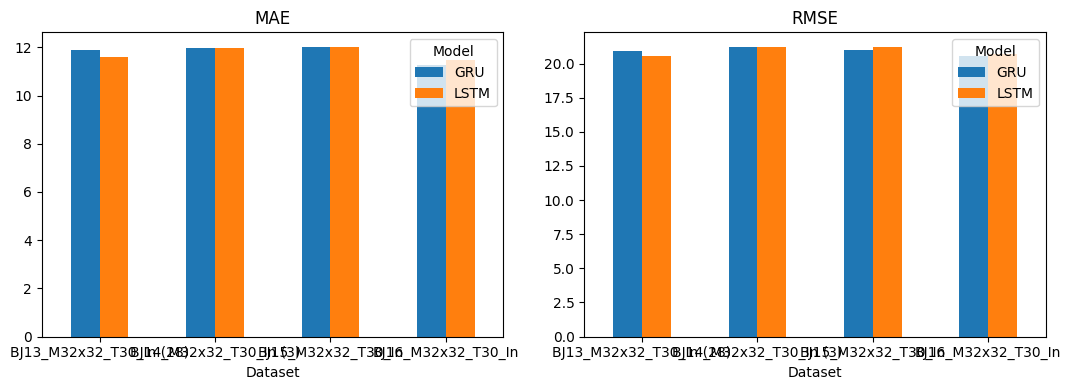

In [4]:
# ===== Colab cell 4: compare LSTM vs GRU =====
import pandas as pd, matplotlib.pyplot as plt
r = pd.concat([pd.read_csv("/content/results/lstm_results.csv"),
               pd.read_csv("/content/results/gru_results.csv")])
print(r.pivot(index="Dataset", columns="Model", values=["MAE", "RMSE"]).round(4))
r.to_csv("/content/results/lstm_vs_gru.csv", index=False)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for a, m in zip(ax, ["MAE", "RMSE"]):
    r.pivot(index="Dataset", columns="Model", values=m).plot.bar(ax=a, title=m, rot=0)
plt.tight_layout(); plt.show()